<a href="https://colab.research.google.com/github/koushikbommasani/Bank-Management-System-with-Multithreading/blob/main/160125737036_160125737009_Bank_Credit_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis and Visualization (EDAV)

## Project Title
**Analyze Deployment of Bank Credit Across Sectors and States**

### Student Details
- **Name:** M.Siddhartha B.Sai koushik
- **Roll Number:** 160125737036 160125737009
- **Department:** Information Technology
- **College:** Chaitanya Bharathi Institute of Technology (CBIT)
- **Project ID:** CEP-17

### Project Overview
This project analyzes the Reserve Bank of India's outstanding bank credit data across states, population groups, and occupational sectors using Python.

### Dataset
**Source:** Reserve Bank of India — Database on Indian Economy (DBIE)

**Dataset:** State, Population Group and Bank Group-wise Classification of Outstanding Credit According to Occupation.

### Tools and Libraries
- Python
- Google Colab
- NumPy
- Pandas
- Matplotlib

### Questions Covered
1. **Q1 – BL3:** Calculate average outstanding credit using NumPy.
2. **Q2 – BL3:** Filter credit data by state and sector using Pandas.
3. **Q3 – BL4:** Identify and impute missing credit records.
4. **Q4 – BL4:** Aggregate outstanding credit by state and sector.
5. **Q5 – BL5:** Analyze credit trends over time using plots.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [66]:
df = pd.read_csv("state_population_group_and_bank_group_wise_cl.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (22468, 120)


/tmp/ipykernel_977/772995701.py:1: DtypeWarning: Columns (9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("state_population_group_and_bank_group_wise_cl.csv")


In [67]:
df.head(10)

,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6,...,c107,c108,c109,c110,c111,c112,c113,c114,c115,c116
0,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,2,"TABLE.NO. 3.8 - STATE, POPULATION GROUP AND B...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,4,( Amount in ₹ Crores),NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,6,State,Region\r\n,Population\r\nGroup,Bank Group\r\n,Occupation,Jun 2026,...,NaN,Dec 2017,NaN,NaN,Sep 2017,NaN,NaN,Jun 2017,NaN,NaN
6,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,7,NaN,NaN,NaN,NaN,NaN,No. of Accounts,...,Amount Outstanding,No. of Accounts,Credit Limit,Amount Outstanding,No. of Accounts,Credit Limit,Amount Outstanding,No. of Accounts,Credit Limit,Amount Outstanding
7,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,8,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PUBLIC SECTOR BANKS,I. AGRICULTURE,3006,...,21,2451,25,22,2548,25,22,2517,25,22
8,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,9,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PRIVATE SECTOR BANKS,I. AGRICULTURE,4,...,1,71,1,1,44,0,0,21,0,0
9,966--table-no-3-8-state-population-group-and-b...,Report 1,full-history,10,Andaman & Nicobar Islands,EASTERN REGION,RURAL,FOREIGN BANKS,I. AGRICULTURE,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
print("Quarter names:")
df.loc[5, "c6":"c15"]


Quarter names:


,5
c6,Jun 2026
c7,NaN
c8,NaN
c9,Mar 2026
c10,NaN
c11,NaN
c12,Dec 2025
c13,NaN
c14,NaN
c15,Sep 2025


In [69]:
print("\nMeasurement names:")
df.loc[6, "c6":"c15"]


Measurement names:


,6
c6,No. of Accounts
c7,Credit Limit
c8,Amount Outstanding
c9,No. of Accounts
c10,Credit Limit
c11,Amount Outstanding
c12,No. of Accounts
c13,Credit Limit
c14,Amount Outstanding
c15,No. of Accounts


In [70]:
# Names of the first 5 columns
descriptive_columns = ["State", "Region", "Population_Group", "Bank_Group", "Occupation"]

# Row 5 = quarter names (written once per 3 columns, so forward-fill the blanks)
# Row 6 = measurement names
quarter_row = df.loc[5, "c6":"c116"].ffill()
measure_row = df.loc[6, "c6":"c116"]

# Join them, e.g. Jun_2026_Amount_Outstanding
clean = lambda s: s.str.strip().str.replace(" ", "_")
quarterly_columns = (clean(quarter_row) + "_" + clean(measure_row)).tolist()

print("Number of descriptive columns:", len(descriptive_columns))
print("Number of quarterly columns:", len(quarterly_columns))
print("\nFirst 9 quarterly column names:")
print(quarterly_columns[:9])

Number of descriptive columns: 5
Number of quarterly columns: 111

First 9 quarterly column names:
['Jun_2026_No._of_Accounts', 'Jun_2026_Credit_Limit', 'Jun_2026_Amount_Outstanding', 'Mar_2026_No._of_Accounts', 'Mar_2026_Credit_Limit', 'Mar_2026_Amount_Outstanding', 'Dec_2025_No._of_Accounts', 'Dec_2025_Credit_Limit', 'Dec_2025_Amount_Outstanding']


In [71]:
# Keep only the data rows (row_no >= 8) and the columns c1 to c116
clean_df = df.loc[df["row_no"] >= 8, "c1":"c116"].copy()

# Give the columns proper names
clean_df.columns = descriptive_columns + quarterly_columns
clean_df = clean_df.reset_index(drop=True)

# Remove extra spaces from the text columns
text_columns = ["State", "Population_Group", "Bank_Group", "Occupation"]
clean_df[text_columns] = clean_df[text_columns].apply(lambda s: s.str.strip())

print("Cleaned dataset shape:", clean_df.shape)
clean_df.iloc[:5, :8]

Cleaned dataset shape: (22461, 116)


,State,Region,Population_Group,Bank_Group,Occupation,Jun_2026_No._of_Accounts,Jun_2026_Credit_Limit,Jun_2026_Amount_Outstanding
0,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PUBLIC SECTOR BANKS,I. AGRICULTURE,3006,65,62
1,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PRIVATE SECTOR BANKS,I. AGRICULTURE,4,0,0
2,Andaman & Nicobar Islands,EASTERN REGION,RURAL,FOREIGN BANKS,I. AGRICULTURE,NaN,NaN,NaN
3,Andaman & Nicobar Islands,EASTERN REGION,RURAL,SMALL FINANCE BANKS,I. AGRICULTURE,NaN,NaN,NaN
4,Andaman & Nicobar Islands,EASTERN REGION,RURAL,ALL SCHEDULED COMMERCIAL BANKS,I. AGRICULTURE,3010,65,62


In [72]:
# Columns that hold numbers
measurement_columns = clean_df.columns[5:]

# Convert text to numbers (values that are not numbers become NaN)
clean_df[measurement_columns] = clean_df[measurement_columns].apply(pd.to_numeric, errors="coerce")

print("Data type conversion completed!")
print(clean_df[measurement_columns].dtypes.head())
clean_df.head()

Data type conversion completed!
Jun_2026_No._of_Accounts       float64
Jun_2026_Credit_Limit          float64
Jun_2026_Amount_Outstanding    float64
Mar_2026_No._of_Accounts       float64
Mar_2026_Credit_Limit          float64
dtype: object


,State,Region,Population_Group,Bank_Group,Occupation,Jun_2026_No._of_Accounts,Jun_2026_Credit_Limit,Jun_2026_Amount_Outstanding,Mar_2026_No._of_Accounts,Mar_2026_Credit_Limit,...,Mar_2018_Amount_Outstanding,Dec_2017_No._of_Accounts,Dec_2017_Credit_Limit,Dec_2017_Amount_Outstanding,Sep_2017_No._of_Accounts,Sep_2017_Credit_Limit,Sep_2017_Amount_Outstanding,Jun_2017_No._of_Accounts,Jun_2017_Credit_Limit,Jun_2017_Amount_Outstanding
0,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PUBLIC SECTOR BANKS,I. AGRICULTURE,3006.0,65.0,62.0,3017.0,63.0,...,21.0,2451.0,25.0,22.0,2548.0,25.0,22.0,2517.0,25.0,22.0
1,Andaman & Nicobar Islands,EASTERN REGION,RURAL,PRIVATE SECTOR BANKS,I. AGRICULTURE,4.0,0.0,0.0,8.0,0.0,...,1.0,71.0,1.0,1.0,44.0,0.0,0.0,21.0,0.0,0.0
2,Andaman & Nicobar Islands,EASTERN REGION,RURAL,FOREIGN BANKS,I. AGRICULTURE,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Andaman & Nicobar Islands,EASTERN REGION,RURAL,SMALL FINANCE BANKS,I. AGRICULTURE,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Andaman & Nicobar Islands,EASTERN REGION,RURAL,ALL SCHEDULED COMMERCIAL BANKS,I. AGRICULTURE,3010.0,65.0,62.0,3025.0,63.0,...,22.0,2522.0,26.0,23.0,2592.0,26.0,23.0,2538.0,25.0,22.0


In [73]:
# Q1: Calculate average outstanding credit using NumPy

# Select the "Amount Outstanding" column of every quarter
amount_columns = [c for c in clean_df.columns if c.endswith("_Amount_Outstanding")]

# Mean of each quarter, ignoring missing values, stored in a NumPy array
average_credit = np.nanmean(clean_df[amount_columns].to_numpy(), axis=0)

print("Average Outstanding Credit by Quarter")
print("-" * 45)
for col, avg in zip(amount_columns, average_credit):
    print(col, ": Rs.", round(avg, 2), "crore")

Average Outstanding Credit by Quarter
---------------------------------------------
Jun_2026_Amount_Outstanding : Rs. 10831.38 crore
Mar_2026_Amount_Outstanding : Rs. 10677.29 crore
Dec_2025_Amount_Outstanding : Rs. 10235.48 crore
Sep_2025_Amount_Outstanding : Rs. 9779.57 crore
Jun_2025_Amount_Outstanding : Rs. 9505.23 crore
Mar_2025_Amount_Outstanding : Rs. 9400.86 crore
Dec_2024_Amount_Outstanding : Rs. 9212.47 crore
Sep_2024_Amount_Outstanding : Rs. 8973.96 crore
Jun_2024_Amount_Outstanding : Rs. 8723.3 crore
Mar_2024_Amount_Outstanding : Rs. 8630.77 crore
Dec_2023_Amount_Outstanding : Rs. 8301.97 crore
Sep_2023_Amount_Outstanding : Rs. 7876.03 crore
Jun_2023_Amount_Outstanding : Rs. 7313.62 crore
Mar_2023_Amount_Outstanding : Rs. 7209.59 crore
Dec_2022_Amount_Outstanding : Rs. 6884.47 crore
Sep_2022_Amount_Outstanding : Rs. 6610.24 crore
Jun_2022_Amount_Outstanding : Rs. 6334.23 crore
Mar_2022_Amount_Outstanding : Rs. 6179.07 crore
Dec_2021_Amount_Outstanding : Rs. 5905.16 crore
Se

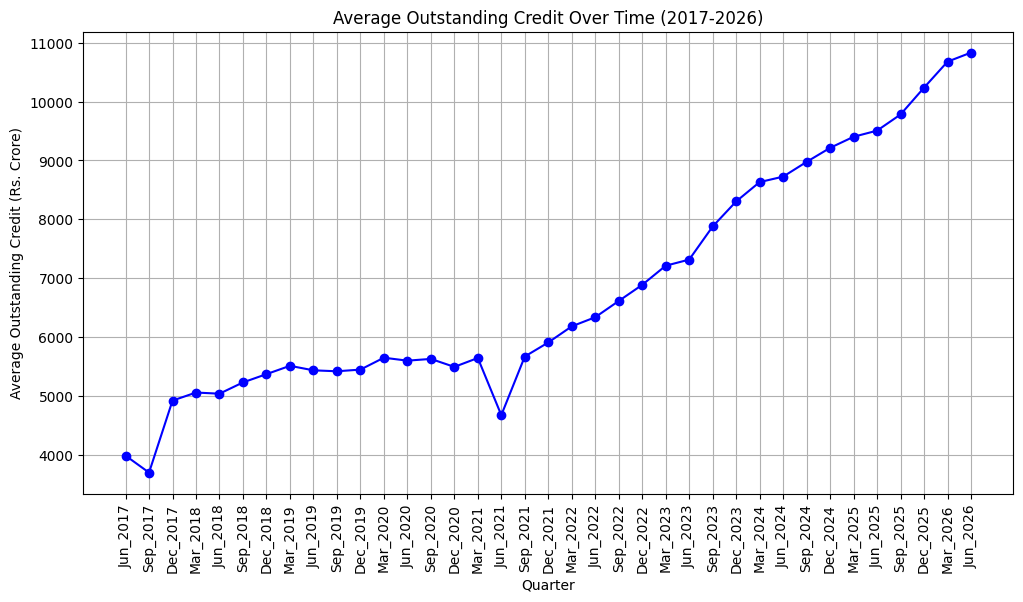

In [74]:
# Q1: Line plot of average outstanding credit over time

# The columns are newest first, so reverse them using slicing
quarters_chronological = amount_columns[::-1]
quarter_labels = [q.replace("_Amount_Outstanding", "") for q in quarters_chronological]

plt.figure(figsize=(12, 6))
plt.plot(quarter_labels, average_credit[::-1], color="blue", marker="o", linestyle="-")
plt.title("Average Outstanding Credit Over Time (2017-2026)")
plt.xlabel("Quarter")
plt.ylabel("Average Outstanding Credit (Rs. Crore)")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Q1. Calculate Average Outstanding Credit

**Bloom's Taxonomy Level:** BL3 – Apply

**Objective:** To calculate the average outstanding credit for each quarter using NumPy and Pandas.

**Methodology:** The 37 quarterly `Amount Outstanding` columns were selected from the cleaned dataset. The mean outstanding credit was calculated for each quarter, and the results were stored in a NumPy array.

**Results:** The average outstanding credit increased from ₹3,981.84 crore in June 2017 to ₹10,831.38 crore in June 2026.

**Visualization:** A line graph was created to display the quarterly changes in average outstanding credit from June 2017 to June 2026.

**Conclusion:** The average outstanding credit across available records generally increased over the study period, although some quarterly fluctuations occurred.

**Limitation:** Each quarterly mean is calculated using the available non-missing records. It represents an average across dataset rows, not the total outstanding credit of India.

In [75]:
# Q2: Filter agricultural credit in Telangana (Boolean indexing)

filtered_df = clean_df[
    (clean_df["State"] == "Telangana") &
    (clean_df["Occupation"] == "I. AGRICULTURE") &
    (clean_df["Bank_Group"] == "ALL SCHEDULED COMMERCIAL BANKS")
]

print("Filtered records:", filtered_df.shape[0])
print(filtered_df[["State", "Population_Group", "Bank_Group", "Occupation"]])


Filtered records: 4
           State Population_Group                      Bank_Group  \
19310  Telangana            RURAL  ALL SCHEDULED COMMERCIAL BANKS   
19316  Telangana       SEMI-URBAN  ALL SCHEDULED COMMERCIAL BANKS   
19323  Telangana            URBAN  ALL SCHEDULED COMMERCIAL BANKS   
19331  Telangana     METROPOLITAN  ALL SCHEDULED COMMERCIAL BANKS   

           Occupation  
19310  I. AGRICULTURE  
19316  I. AGRICULTURE  
19323  I. AGRICULTURE  
19331  I. AGRICULTURE  


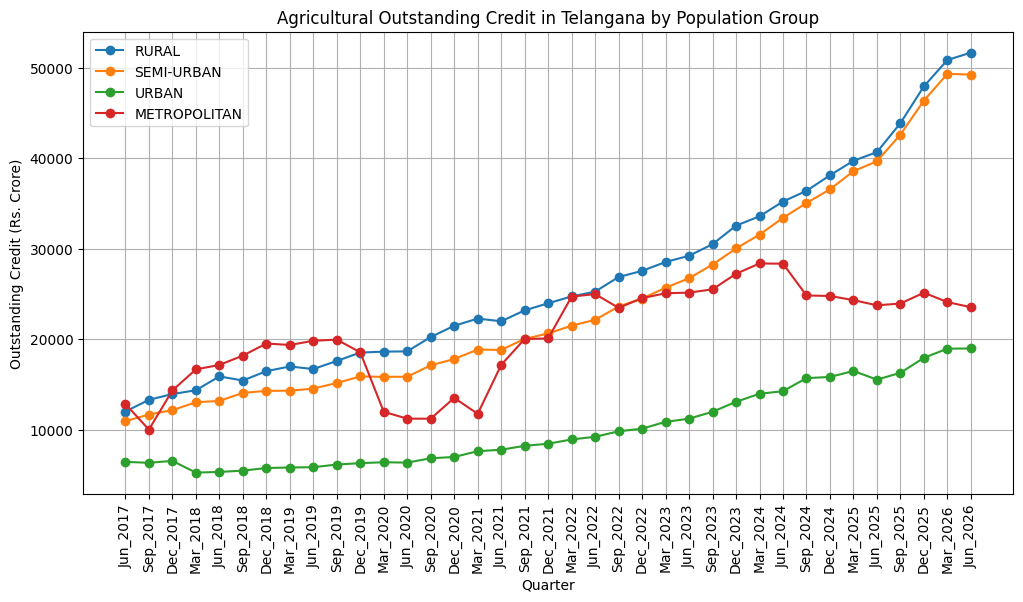

In [76]:
# Q2: Compare agricultural credit by population group

quarters_chronological = amount_columns[::-1]
quarter_labels = [q.replace("_Amount_Outstanding", "") for q in quarters_chronological]

plt.figure(figsize=(12, 6))
for _, row in filtered_df.iterrows():
    plt.plot(quarter_labels, row[quarters_chronological], marker="o", label=row["Population_Group"])

plt.title("Agricultural Outstanding Credit in Telangana by Population Group")
plt.xlabel("Quarter")
plt.ylabel("Outstanding Credit (Rs. Crore)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.show()

### Q2. Filter Credit Data by State and Sector

**Bloom's Taxonomy Level:** BL3 – Apply

**Objective:** To filter the dataset and analyze agricultural outstanding credit in Telangana across different population groups.

**Methodology:** Pandas Boolean indexing was used to select records where the state was Telangana, the occupation was Agriculture, and the bank group was All Scheduled Commercial Banks.

**Results:** Four records were selected, representing Rural, Semi-Urban, Urban, and Metropolitan population groups.

**Visualization:** A line graph was plotted to compare quarterly agricultural outstanding credit across the four population groups from June 2017 to June 2026.

**Conclusion:** Filtering allows us to examine agricultural credit in a specific state and compare its distribution across population groups over time.

In [77]:
# Q3: Identify missing values

measurement_columns = clean_df.columns[5:]
data = clean_df[measurement_columns]

# Count missing values in each column
missing_per_column = data.isnull().sum()

total_missing = missing_per_column.sum()
total_values = data.size
missing_percentage = total_missing / total_values * 100

# dropna() removes rows that have missing values
complete_rows = len(data.dropna())
rows_with_some_data = len(data.dropna(how="all"))

print("Total records:", clean_df.shape[0])
print("Records with no missing values:", complete_rows)
print("Records with at least one value:", rows_with_some_data)
print("Total missing values:", total_missing)
print("Percentage of missing values:", round(missing_percentage, 2), "%")

print("\nTop 10 columns with the most missing values:")
print(missing_per_column.sort_values(ascending=False).head(10))

Total records: 22461
Records with no missing values: 7820
Records with at least one value: 15956
Total missing values: 1336536
Percentage of missing values: 53.61 %

Top 10 columns with the most missing values:
Dec_2017_Credit_Limit          13277
Dec_2017_No._of_Accounts       13277
Dec_2017_Amount_Outstanding    13277
Mar_2018_Amount_Outstanding    13064
Mar_2018_No._of_Accounts       13064
Mar_2018_Credit_Limit          13064
Jun_2018_Credit_Limit          13030
Jun_2018_Amount_Outstanding    13030
Jun_2018_No._of_Accounts       13030
Sep_2018_No._of_Accounts       13020
dtype: int64


In [78]:
# Q3: Fill missing values with the column mean (fillna)

imputed_df = clean_df.copy()
imputed_df[measurement_columns] = imputed_df[measurement_columns].fillna(imputed_df[measurement_columns].mean())

missing_before = clean_df[measurement_columns].isnull().sum().sum()
missing_after = imputed_df[measurement_columns].isnull().sum().sum()

print("Missing values before:", missing_before)
print("Missing values after:", missing_after)
print("Values filled:", missing_before - missing_after)
print("Missing percentage before:", round(missing_before / total_values * 100, 2), "%")
print("Missing percentage after:", round(missing_after / total_values * 100, 2), "%")

Missing values before: 1336536
Missing values after: 0
Values filled: 1336536
Missing percentage before: 53.61 %
Missing percentage after: 0.0 %


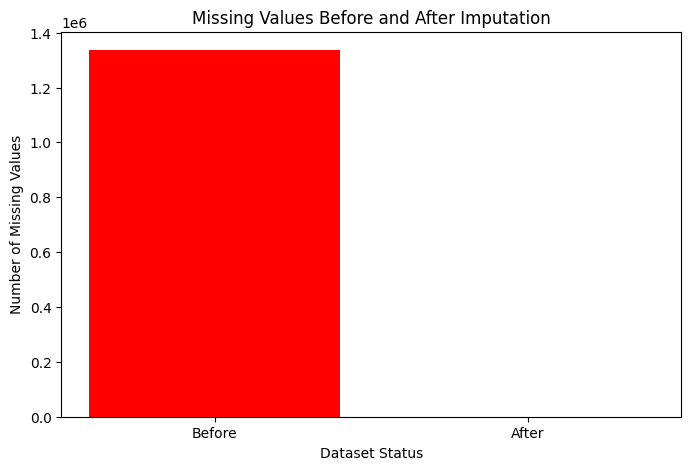

In [79]:
# Q3: Bar chart of missing values before and after

labels = ["Before", "After"]
counts = [missing_before, missing_after]

plt.figure(figsize=(8, 5))
plt.bar(labels, counts, color=["red", "green"])
plt.title("Missing Values Before and After Imputation")
plt.xlabel("Dataset Status")
plt.ylabel("Number of Missing Values")
plt.show()


### Q3. Identify and Impute Missing Credit Records

**Bloom's Taxonomy Level:** BL4 – Analyze

**Objective:** To identify missing quarterly credit measurements and fill them using a suitable value.

**Methodology:** Pandas isnull().sum() was used to count the missing values in the quarterly measurement columns, and dropna() was used to find complete records. The missing values of each column were then filled with the mean of that column using fillna().

**Results:**
- Missing values before imputation: 1,336,536 (53.61%).
- Missing values after imputation: see the output of the imputation cell.
- Values filled: see the output of the imputation cell.

**Visualization:** A bar chart compares the number of missing measurement values before and after filling.

**Conclusion:** Filling with the column mean removed the missing values from the measurement columns, so the data is ready for further analysis.

**Limitation:** Imputed values are estimates, not actual RBI observations. Missing records do not necessarily indicate zero credit.

In [80]:
# Q4: Aggregate outstanding credit by state and sector

# The eight broad sectors
sectors = [
    "I. AGRICULTURE",
    "II. INDUSTRY",
    "III. TRANSPORT OPERATORS",
    "IV. PROFESSIONAL AND OTHER SERVICES",
    "V. PERSONAL LOANS",
    "VI. TRADE",
    "VII. FINANCE",
    "VIII. ALL OTHERS"
]

# Keep only All Scheduled Commercial Banks and the eight sectors
bank_df = clean_df[
    (clean_df["Bank_Group"] == "ALL SCHEDULED COMMERCIAL BANKS") &
    (clean_df["Occupation"].isin(sectors))
]

# Group by state and sector, then add up the credit
q4_aggregated = bank_df.groupby(["State", "Occupation"])[amount_columns].sum().reset_index()
q4_aggregated = q4_aggregated.rename(columns={"Occupation": "Sector"})

print("Filtered records:", bank_df.shape[0])
print("Aggregated state-sector records:", q4_aggregated.shape[0])
print("Number of sectors:", len(sectors))
print("Number of states/territories:", q4_aggregated["State"].nunique())

print(q4_aggregated[["State", "Sector", "Jun_2026_Amount_Outstanding"]].head(10))

Filtered records: 1216
Aggregated state-sector records: 304
Number of sectors: 8
Number of states/territories: 38
                       State                               Sector  \
0  Andaman & Nicobar Islands                       I. AGRICULTURE   
1  Andaman & Nicobar Islands                         II. INDUSTRY   
2  Andaman & Nicobar Islands             III. TRANSPORT OPERATORS   
3  Andaman & Nicobar Islands  IV. PROFESSIONAL AND OTHER SERVICES   
4  Andaman & Nicobar Islands                    V. PERSONAL LOANS   
5  Andaman & Nicobar Islands                            VI. TRADE   
6  Andaman & Nicobar Islands                         VII. FINANCE   
7  Andaman & Nicobar Islands                     VIII. ALL OTHERS   
8             Andhra Pradesh                       I. AGRICULTURE   
9             Andhra Pradesh                         II. INDUSTRY   

   Jun_2026_Amount_Outstanding  
0                        420.0  
1                        157.0  
2                        18

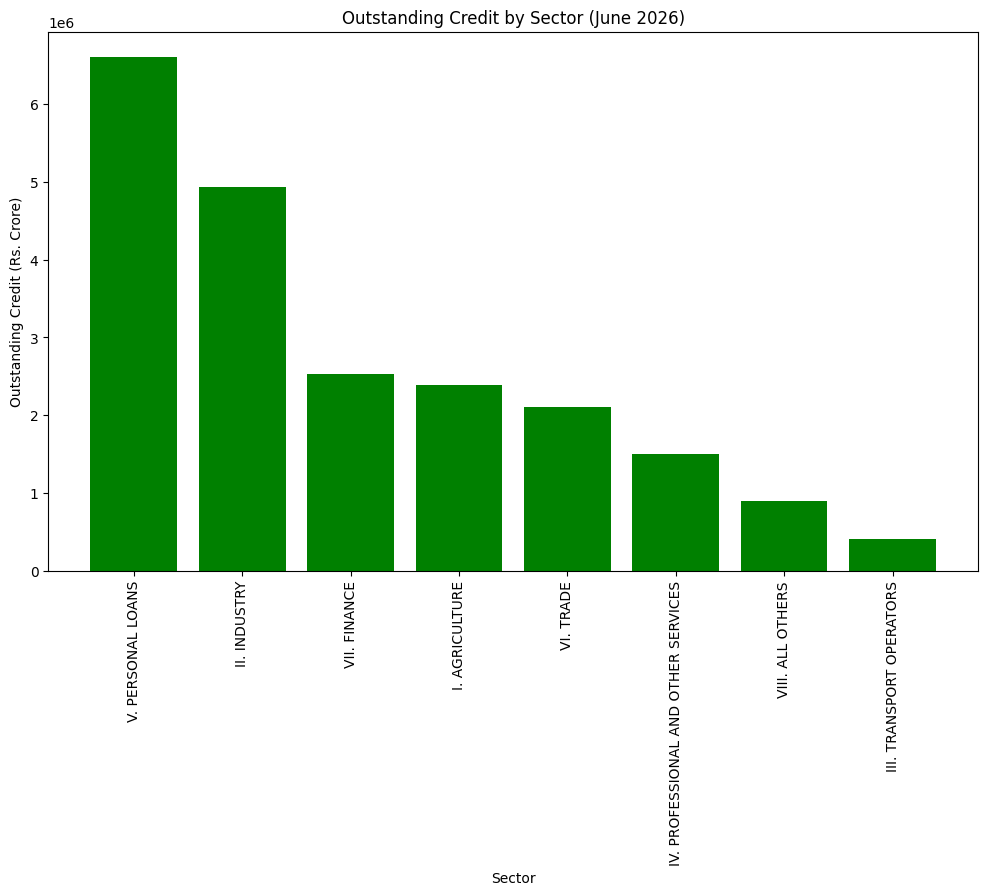

Sector
V. PERSONAL LOANS                      6603573.0
II. INDUSTRY                           4937130.0
VII. FINANCE                           2533190.0
I. AGRICULTURE                         2390129.0
VI. TRADE                              2104339.0
IV. PROFESSIONAL AND OTHER SERVICES    1496200.0
VIII. ALL OTHERS                        893656.0
III. TRANSPORT OPERATORS                401627.0
Name: Jun_2026_Amount_Outstanding, dtype: float64


In [81]:
# Q4: Compare credit across sectors in June 2026

latest_quarter = "Jun_2026_Amount_Outstanding"

sector_totals = q4_aggregated.groupby("Sector")[latest_quarter].sum()
sector_totals = sector_totals.sort_values(ascending=False)

plt.figure(figsize=(12, 7))
plt.bar(sector_totals.index, sector_totals.values, color="green")
plt.title("Outstanding Credit by Sector (June 2026)")
plt.xlabel("Sector")
plt.ylabel("Outstanding Credit (Rs. Crore)")
plt.xticks(rotation=90)
plt.show()

print(sector_totals)


### Q4. Aggregate Outstanding Credit by State and Sector

**Bloom's Taxonomy Level:** BL4 – Analyze

**Objective:** To analyze the distribution of outstanding credit across states and eight broad occupational sectors.

**Methodology:** Pandas grouping and aggregation were used to group records by state and sector. Only All Scheduled Commercial Banks were selected, and credit across population groups was summed to avoid double-counting bank groups.

**Results:** The filtered dataset contained 1,216 records, which were aggregated into 304 state-sector combinations across 38 states and territories.

For June 2026:
- Personal Loans: ₹66,03,573 crore
- Industry: ₹49,37,130 crore
- Finance: ₹25,33,190 crore
- Agriculture: ₹23,90,129 crore
- Transport Operators: ₹4,01,627 crore

**Visualization:** A bar chart compares outstanding credit across the eight sectors for June 2026.

**Conclusion:** Personal Loans had the highest reported outstanding credit, while Transport Operators had the lowest among the eight sectors.

**Limitation:** The totals are based on available state-level records. Missing values were not treated as zero, and the results represent outstanding credit rather than credit disbursements.

In [82]:
# Q5: Quarterly outstanding credit by sector

quarters_chronological = amount_columns[::-1]

sector_trends = q4_aggregated.groupby("Sector")[quarters_chronological].sum()

print("Number of sectors:", sector_trends.shape[0])
print("Number of quarters:", sector_trends.shape[1])
print(sector_trends[["Jun_2017_Amount_Outstanding", "Jun_2026_Amount_Outstanding"]])


Number of sectors: 8
Number of quarters: 37
                                     Jun_2017_Amount_Outstanding  \
Sector                                                             
I. AGRICULTURE                                          928431.0   
II. INDUSTRY                                           2907912.0   
III. TRANSPORT OPERATORS                                158006.0   
IV. PROFESSIONAL AND OTHER SERVICES                     582467.0   
V. PERSONAL LOANS                                      1602248.0   
VI. TRADE                                               722238.0   
VII. FINANCE                                            531442.0   
VIII. ALL OTHERS                                        186089.0   

                                     Jun_2026_Amount_Outstanding  
Sector                                                            
I. AGRICULTURE                                         2390129.0  
II. INDUSTRY                                           4937130.0  
III. TR

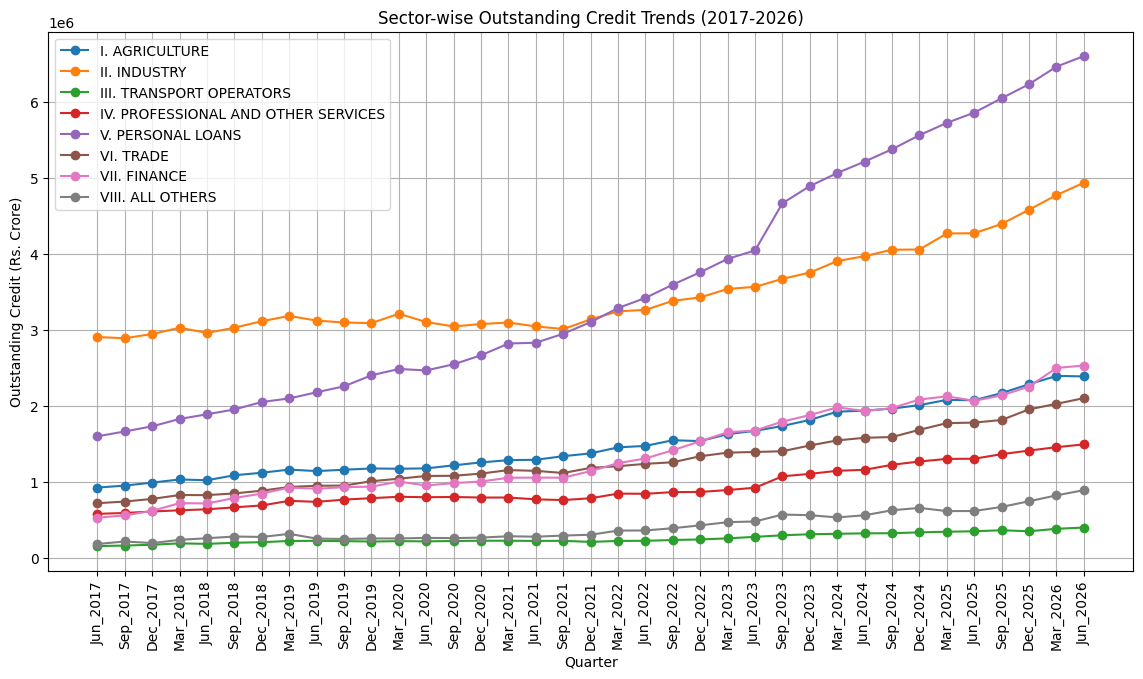

In [83]:
# Q5: Line plot of credit trends for each sector

quarter_labels = [q.replace("_Amount_Outstanding", "") for q in quarters_chronological]

plt.figure(figsize=(14, 7))
for sector, values in sector_trends.iterrows():
    plt.plot(quarter_labels, values, marker="o", label=sector)

plt.title("Sector-wise Outstanding Credit Trends (2017-2026)")
plt.xlabel("Quarter")
plt.ylabel("Outstanding Credit (Rs. Crore)")
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.show()

In [84]:
# Q5: Percentage growth in outstanding credit (Jun 2017 to Jun 2026)

growth_df = sector_trends[["Jun_2017_Amount_Outstanding", "Jun_2026_Amount_Outstanding"]].copy()
growth_df.columns = ["Credit_Jun_2017", "Credit_Jun_2026"]

# Add a new column for growth
growth_df["Growth_Percentage"] = (growth_df["Credit_Jun_2026"] - growth_df["Credit_Jun_2017"]) / growth_df["Credit_Jun_2017"] * 100

growth_df = growth_df.sort_values(by="Growth_Percentage", ascending=False)
print(growth_df.round(2))

print("\nSector with the highest percentage growth:")
print(growth_df.head(1).round(2))

                                     Credit_Jun_2017  Credit_Jun_2026  \
Sector                                                                  
VIII. ALL OTHERS                            186089.0         893656.0   
VII. FINANCE                                531442.0        2533190.0   
V. PERSONAL LOANS                          1602248.0        6603573.0   
VI. TRADE                                   722238.0        2104339.0   
I. AGRICULTURE                              928431.0        2390129.0   
IV. PROFESSIONAL AND OTHER SERVICES         582467.0        1496200.0   
III. TRANSPORT OPERATORS                    158006.0         401627.0   
II. INDUSTRY                               2907912.0        4937130.0   

                                     Growth_Percentage  
Sector                                                  
VIII. ALL OTHERS                                380.23  
VII. FINANCE                                    376.66  
V. PERSONAL LOANS                        

### Q5. Analyze Outstanding Credit Trends Over Time

**Bloom's Taxonomy Level:** BL5 – Evaluate

**Objective:** To evaluate changes in outstanding credit across eight sectors over 37 quarters, from June 2017 to June 2026.

**Methodology:** Pandas was used to aggregate outstanding credit by sector and quarter. A multi-line graph was created to compare quarterly trends. Percentage growth was calculated by comparing June 2017 and June 2026 values.

**Results:**
- All Others recorded the highest percentage growth at 380.23%.
- Finance recorded growth of 376.66%.
- Personal Loans recorded growth of 312.14%.
- Industry recorded the lowest percentage growth at 69.78%.
- Personal Loans had the highest outstanding credit in June 2026, at ₹66,03,573 crore.

**Visualization:** A line graph illustrates quarterly trends across eight sectors. A percentage-growth table compares outstanding credit between June 2017 and June 2026.

**Conclusion:** Outstanding credit increased across all eight sectors between the two comparison dates. All Others and Finance experienced the highest percentage growth, while Personal Loans had the highest outstanding credit in June 2026.

**Limitation:** Percentage growth compares only the two endpoint quarters; it does not describe every fluctuation during the period. Totals depend on the available state-level records, and missing values were not treated as zero.

# Overall Project Conclusion

## Project: Analyze Deployment of Bank Credit Across Sectors and States

This project analyzed the Reserve Bank of India's state-wise, population-group-wise, and bank-group-wise outstanding credit dataset using Python, NumPy, Pandas, and Matplotlib.

The five questions explored average outstanding credit, filtering by state and sector, missing-value analysis and imputation, state-sector aggregation, and credit trends over time.

### Key Findings

1. **Average Credit:** The average outstanding credit across available dataset rows generally increased between June 2017 and June 2026.

2. **State and Sector Filtering:** Agricultural outstanding credit in Telangana was filtered and compared across Rural, Semi-Urban, Urban, and Metropolitan population groups.

3. **Missing Values:** The dataset initially contained 1,336,536 missing measurement values. The missing values were then filled with the column mean using fillna().

4. **Sector-wise Analysis:** Personal Loans recorded the highest outstanding credit in June 2026, at ₹66,03,573 crore, followed by Industry at ₹49,37,130 crore.

5. **Credit Growth:** Between June 2017 and June 2026, All Others recorded the highest percentage growth at 380.23%, followed by Finance at 376.66%.

### Learning Outcomes

Through this project, we applied:
- **NumPy:** Array operations and numerical calculations.
- **Pandas:** Data cleaning, filtering, missing-value handling, grouping, and aggregation.
- **Matplotlib:** Line graphs and bar charts for visual analysis.
- **Data Analysis:** Interpretation of sector-wise credit patterns and changes over time.

### Final Conclusion

The analysis demonstrates how Python-based exploratory data analysis can help examine outstanding bank credit across sectors, states, population groups, and quarters. The findings indicate an overall increase in outstanding credit between the selected comparison dates, with differences in both credit volume and percentage growth across sectors.

**Note:** The dataset represents outstanding credit, not necessarily credit disbursements. Missing observations and filled (imputed) estimates must be considered when interpreting the results.